Q1. In a reactor the reaction A+B=C reaches equilibrium. Initial concentration are [A]0=1.5, [B]0=1.0, [C]0=0 mol/L. if X mol/L of C is formed, kc=x/((1.5-x)(1-x)),which rearranges to the quadratic equation kc.x^2-(2.5kc+1).x+1.5kc=0
write a python program that:
(a) reads kc using input(), print the data type of the raw input and of the converted value, and shows a clear message (no crash) if the text is not a number otr if kc<=0;
(b)finds a,b,c, the discriminant and both roots;
(c)select the physically meanigful root(0<=x<=, beacause B is limiting);
(d)prints equilibrium [A],[B],[C](3 decimals)and the conversion of the limiting reactant B=x/[B]0 * 100(%)
(e)classifie the conversion using if /elif/else: >=70% "High", >= 40% 'Moderate",otherwise "Low".
tesst with kc=4, kc=0.5,kc=-2

In [10]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: please enter Kc as a number.")
else:
    print("Converted value type:", type(kc))

    if kc <= 0:
        print("Error: Kc must be greater than 0.")
    else:
        # kc*x^2 - (2.5*kc + 1)*x + 1.5*kc = 0
        a = kc
        b = -(2.5 * kc + 1)
        c = 1.5 * kc

        discriminant = b**2 - 4 * a * c
        square_root = math.sqrt(discriminant)
        root_1 = (-b + square_root) / (2 * a)
        root_2 = (-b - square_root) / (2 * a)

        print(f"a = {a}, b = {b}, c = {c}")
        print(f"Discriminant = {discriminant}")
        print(f"Root 1 = {root_1}")
        print(f"Root 2 = {root_2}")

        physical_roots = [root for root in (root_1, root_2) if 0 <= root <= 1]

        if not physical_roots:
            print("Error: no physical root found in the range 0 <= x <= 1.")
        else:
            x = physical_roots[0]
            equilibrium_a = 1.5 - x
            equilibrium_b = 1.0 - x
            equilibrium_c = x
            conversion = (x / 1.0) * 100

            print(f"Equilibrium [A] = {equilibrium_a:.3f} mol/L")
            print(f"Equilibrium [B] = {equilibrium_b:.3f} mol/L")
            print(f"Equilibrium [C] = {equilibrium_c:.3f} mol/L")
            print(f"Conversion of B = {conversion:.3f}%")

            if conversion >= 70:
                classification = "High"
            elif conversion >= 40:
                classification = "Moderate"
            else:
                classification = "Low"

            print("Classification:", classification)

Raw input type: <class 'str'>
Converted value type: <class 'float'>
a = 0.5, b = -2.25, c = 0.75
Discriminant = 3.5625
Root 1 = 4.1374586088176875
Root 2 = 0.36254139118231254
Equilibrium [A] = 1.137 mol/L
Equilibrium [B] = 0.637 mol/L
Equilibrium [C] = 0.363 mol/L
Conversion of B = 36.254%
Classification: Low


Q2. Part A. In a batch reactur, reactants A is consumed by a first - order reactiopn, dc/dt=-kc. Use the euler method:C-new=C-old-k.C-old. dt. Take C0= 2.5 mol/L, k= 0.04 min^-1, dt=1 min.
(i) Using a for loop, simulate 12 minutes and print a table of time(min), Concentraion(mol/L) and conversion(%).
(ii) Using math.exp(), calculate the exact value C0e^(-kt) at 12 min and print the absolute error of the euler result.
(iii) Using a while loop , repeat the simulation until conversion reaches 40% or time reaches 100 min. Print the time needed and the final concentration.
Part B . Distilation-column samplke code such as DIST2026X9Q3 are stored as text. write a program that reads a code, loops through each character, and print the number of digit and the sum of the digits. Show a message for a empty code and for a code with no digits . Test with DIST2026X9Q3 , an empty code and ABCDEF.

In [4]:
import math

# Part A: Euler simulation for the first-order reaction
initial_concentration = 2.5
rate_constant = 0.04
time_step = 1.0

print("Part A(i): Euler simulation")
print("Time (min)\tConcentration (mol/L)\tConversion (%)")
concentration = initial_concentration
conversion = 0.0
print(f"0\t\t{concentration:.4f}\t\t\t{conversion:.2f}")

for time in range(1, 13):
    concentration = concentration - rate_constant * concentration * time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time}\t\t{concentration:.4f}\t\t\t{conversion:.2f}")

exact_concentration = initial_concentration * math.exp(-rate_constant * 12)
absolute_error = abs(concentration - exact_concentration)
print(f"\nExact concentration at 12 min = {exact_concentration:.6f} mol/L")
print(f"Absolute error at 12 min = {absolute_error:.6f} mol/L")

# Part A(iii): Continue until conversion reaches 40% or time reaches 100 min
while_concentration = initial_concentration
while_time = 0
while_conversion = 0.0

while while_conversion < 40 and while_time < 100:
    while_concentration = (
        while_concentration
        - rate_constant * while_concentration * time_step
    )
    while_time += 1
    while_conversion = (
        (initial_concentration - while_concentration)
        / initial_concentration
        * 100
    )

print("\nPart A(iii): 40% conversion stopping condition")
print(f"Time needed = {while_time} min")
print(f"Final concentration = {while_concentration:.4f} mol/L")
print(f"Final conversion = {while_conversion:.2f}%")

# Part B: Count the digits in a distillation-column code
sample_code = input("Enter a distillation-column code: ")

if sample_code == "":
    print("Error: the code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in sample_code:
        if character.isdecimal():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("The code contains no digits.")
    else:
        print(f"Number of digits = {digit_count}")
        print(f"Sum of digits = {digit_sum}")

Part A(i): Euler simulation
Time (min)	Concentration (mol/L)	Conversion (%)
0		2.5000			0.00
1		2.4000			4.00
2		2.3040			7.84
3		2.2118			11.53
4		2.1234			15.07
5		2.0384			18.46
6		1.9569			21.72
7		1.8786			24.86
8		1.8035			27.86
9		1.7313			30.75
10		1.6621			33.52
11		1.5956			36.18
12		1.5318			38.73

Exact concentration at 12 min = 1.546958 mol/L
Absolute error at 12 min = 0.015184 mol/L

Part A(iii): 40% conversion stopping condition
Time needed = 13 min
Final concentration = 1.4705 mol/L
Final conversion = 41.18%
The code contains no digits.


Q3. Part A. A laboratory has n candidates solvents and wants to test r of them together in a mixed solvent (order does not matter). Write a recusrive function factorial(n)(remember the base case for 0!) and a function combination(n,r)=n!/(r! (n-r)!) that uses it. Reject invalid (negative value , r>n). Print the number for n=6, r=8.
Part B. During a crystallisation run, sample are taken at times= Fibonacci number*4min. Write an iterative function fib_iter(n) that returens a list of the first n Fibonacci numbers, and a recursive function fib_rec(k) that returns the k-th fibonacci number (F0=0, F1= 1). For n=10, check that both functions agree and print a table: sample No.| fIBONACCI TAG | Sampling time(min).

In [8]:
# Part A: Recursive factorial and combination

def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative integers.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Invalid values: require n >= 0 and 0 <= r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


n = 6
r = 8
try:
    print(f"Number of combinations for n={n}, r={r}: {combination(n, r)}")
except ValueError as error:
    print(f"Cannot calculate combinations for n={n}, r={r}: {error}")


# Part B: Iterative and recursive Fibonacci functions

def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")

    numbers = []
    first, second = 0, 1
    for _ in range(n):
        numbers.append(first)
        first, second = second, first + second
    return numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


sample_count = 10
fibonacci_numbers = fib_iter(sample_count)

if all(fibonacci_numbers[k] == fib_rec(k) for k in range(sample_count)):
    print("\nIterative and recursive Fibonacci results agree.")
    print("Sample No.\tFibonacci Tag\tSampling Time (min)")
    for sample_number, fibonacci_tag in enumerate(fibonacci_numbers, start=1):
        sampling_time = fibonacci_tag * 4
        print(f"{sample_number}\t\t{fibonacci_tag}\t\t{sampling_time}")
else:
    print("The Fibonacci results do not agree.")

Cannot calculate combinations for n=6, r=8: Invalid values: require n >= 0 and 0 <= r <= n.

Iterative and recursive Fibonacci results agree.
Sample No.	Fibonacci Tag	Sampling Time (min)
1		0		0
2		1		4
3		1		4
4		2		8
5		3		12
6		5		20
7		8		32
8		13		52
9		21		84
10		34		136


Q4. Consumption of a reactant was studied in a batch reactor with two feed concentration of the catalyst. The concentration (mol/L) was recorded:
Time_min: [0,10,20,30,40,50]
Run1_mol_L (low catalyst): [1.50,1.17,0.91,0.71,0.55,0.43]
Run2_mol_L(high catalyst): [1.50,0.96,0.61,0.39,0.25,0.16]

(a) Create a data frame from this table . Save its as kinetics.csv(without the index column) and as kinetics.json . Read the csv back and print its shape and data type. 
(b) Print the mean and standard deviation of Run1 and Run2 , and state which run show more variation.
(c) Plot both runs on one graph (Time on x-axis) with title, axis labels with units, legend and grid.
(d) Ethylene gas is compressed slowly in a piston-cylinder at constant temperature:
Volumn_L : [1,2,3,4,5]
Pressure_bar : [5.03,2.52,1.65,1.26,1.01]

Plot prssure vs. volume as a scatter plot. calculate k as the mean of the P*V and draw the reference curve P=k/V on the same graph. Add title, labels with units and legend.

CSV shape: (6, 3)
CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run 1 mean = 0.878 mol/L
Run 1 standard deviation = 0.402 mol/L
Run 2 mean = 0.645 mol/L
Run 2 standard deviation = 0.507 mol/L
Run 2 shows more variation (larger standard deviation).


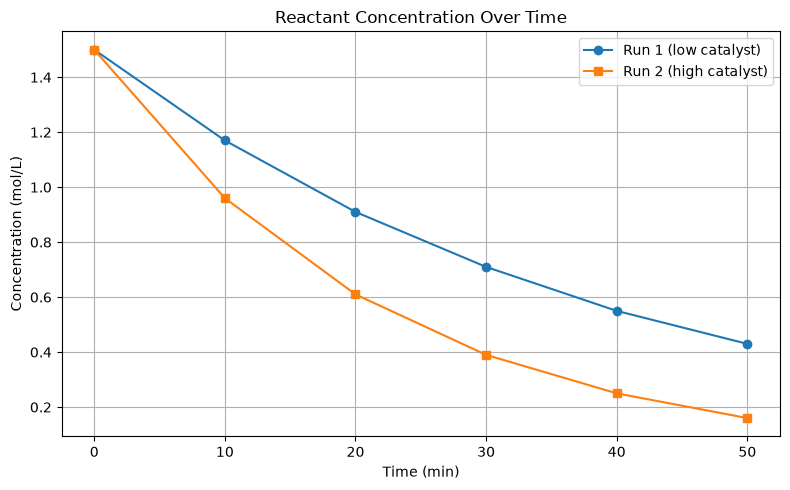


Mean P*V constant, k = 5.022 bar L


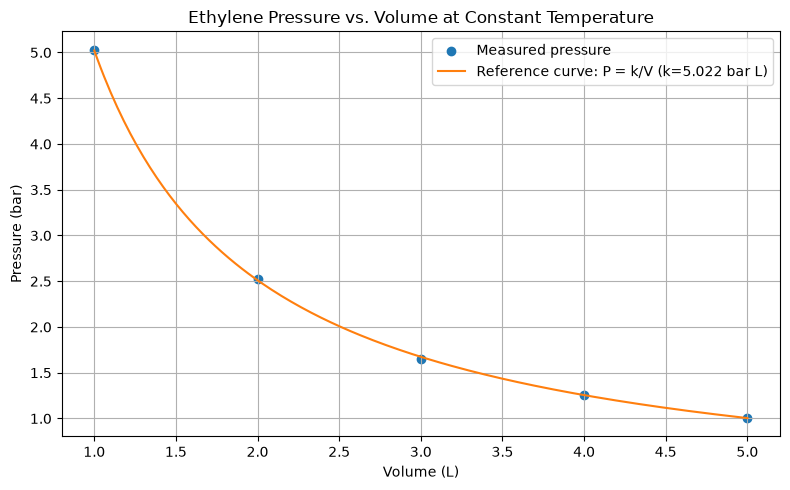

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Part A: Store and analyze the reaction kinetics data
kinetics = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "Run2_mol_L": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
})

kinetics.to_csv("kinetics.csv", index=False)
kinetics.to_json("kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

run1_mean = kinetics["Run1_mol_L"].mean()
run1_std = kinetics["Run1_mol_L"].std()
run2_mean = kinetics["Run2_mol_L"].mean()
run2_std = kinetics["Run2_mol_L"].std()

print(f"\nRun 1 mean = {run1_mean:.3f} mol/L")
print(f"Run 1 standard deviation = {run1_std:.3f} mol/L")
print(f"Run 2 mean = {run2_mean:.3f} mol/L")
print(f"Run 2 standard deviation = {run2_std:.3f} mol/L")

if run1_std > run2_std:
    print("Run 1 shows more variation (larger standard deviation).")
elif run2_std > run1_std:
    print("Run 2 shows more variation (larger standard deviation).")
else:
    print("Both runs have the same standard deviation.")

plt.figure(figsize=(8, 5))
plt.plot(kinetics["Time_min"], kinetics["Run1_mol_L"], marker="o", label="Run 1 (low catalyst)")
plt.plot(kinetics["Time_min"], kinetics["Run2_mol_L"], marker="s", label="Run 2 (high catalyst)")
plt.title("Reactant Concentration Over Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Part B: Pressure-volume data and ideal reference curve
volume_l = np.array([1, 2, 3, 4, 5], dtype=float)
pressure_bar = np.array([5.03, 2.52, 1.65, 1.26, 1.01], dtype=float)

k = np.mean(pressure_bar * volume_l)
print(f"\nMean P*V constant, k = {k:.3f} bar L")

volume_curve = np.linspace(volume_l.min(), volume_l.max(), 200)
pressure_curve = k / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(volume_l, pressure_bar, color="tab:blue", label="Measured pressure")
plt.plot(volume_curve, pressure_curve, color="tab:orange", label=f"Reference curve: P = k/V (k={k:.3f} bar L)")
plt.title("Ethylene Pressure vs. Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()